In [1076]:
import sys
sys.path.append('../')

In [1077]:
# !{sys.executable} -m pip install findicator
# !{sys.executable} -m pip install matplotlib
# !{sys.executable} -m pip install gym

In [1078]:
from ice_fx.infrastructure.instrument_collection import instrumentCollection as ic
from ice_fx.oanda_api.oanda_api import OandaApi
from ice_fx.infrastructure.collect_data import run_collection
from findicator import (atr, bollinger_bands, macd, impulse_system, ema_channel,
                        elder_ray, stochastic_oscillator, force_index, rsi)
# from findicator import stochastic_oscillator
from chronofusion.utils.errors import InvalidArgumentError, NonOverlappingData, NotAvailableData, WrongMode

# api = OandaApi()
# ic.create_file(api.get_account_instruments(), "./test_env_data")
# ic.load_instruments("./test_env_data")
# ic.print_instruments()
from collections import deque, namedtuple
import torch
import torch.nn as nn
import time
import random
from tqdm import tqdm
import torch.optim as optim
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.preprocessing import StandardScaler

import numpy as np
import pandas as pd
import gym
from gym import spaces
# import talib
from typing import Tuple, Dict, List
import warnings
warnings.filterwarnings('ignore')
import joblib



# Environment

In [1079]:
import pandas as pd
m5_data = pd.read_pickle('./test_env_data/EUR_USD_M5.pkl')
m30_data = pd.read_pickle('./test_env_data/EUR_USD_M30.pkl')



In [1080]:
m30_data_filtered = m30_data[['time', 'volume', 'mid_o', 'mid_h', 'mid_l', 'mid_c']].copy()
m5_data_filtered = m5_data[['time', 'volume', 'mid_o', 'mid_h', 'mid_l', 'mid_c']].copy()

In [1081]:
115000/300

383.3333333333333

## Window Generator

In [ ]:
class TimeFrameWindowGen:
    def __init__(self, 
                 higher_tf_data:pd.DataFrame, 
                 lower_tf_data:pd.DataFrame, 
                 higher_window_size:int = 50, 
                 lower_window_size:int = 50,
                 htf_start_index=0,
                 test=False,
                 n_candles_to_test:int=None):
        
        if test and not n_candles_to_test:
            raise InvalidArgumentError('Specify the n_candles_to_test!')
        # self.timestep = 0
        self.htf_data = higher_tf_data
        self.ltf_data = lower_tf_data
        self.h_window_size = higher_window_size
        self.l_window_size = lower_window_size
        self.lower_last_candle_index_for_test=None
        self.n_candles_to_test = n_candles_to_test
        self.htf_start_index = htf_start_index
        self.test = test
        self.alignment(htf_start_index=htf_start_index)

    def alignment(self, htf_start_index: int):
        self.higher_last_candle_index = self.h_window_size - 1 + htf_start_index
        if self.higher_last_candle_index >= self.htf_data.shape[0]:
            raise NotAvailableData(index=self.higher_last_candle_index, data_frame_scale='higher')
        time_to_align = self.htf_data['time'].iloc[self.higher_last_candle_index]
        # print(self.htf_data.iloc[self.higher_last_candle_index])
        aligned_index = self.ltf_data.index[self.ltf_data["time"] == time_to_align]
        if aligned_index.empty:
            raise NonOverlappingData()
        else:
            self.lower_last_candle_index = aligned_index[0]
            if self.test:
                self.lower_last_candle_index_for_test = aligned_index[0] + self.n_candles_to_test

    def reset(self, idx=None):
        if idx:
            self.alignment(idx)
        else:
            self.alignment(self.htf_start_index)

    
    def generate(self):
        
        start = self.higher_last_candle_index - self.h_window_size + 1
        end = self.higher_last_candle_index + 1
        if end >= self.htf_data.shape[0]:
            raise NotAvailableData(index=end, data_frame_scale='higher')
        if start >= self.htf_data.shape[0]:
            raise NotAvailableData(index=start, data_frame_scale='higher')
        
        higher_fraction = self.htf_data[start:end]


        start = self.lower_last_candle_index - self.l_window_size + 1 
        end = self.lower_last_candle_index + 1

        

        if end >= self.ltf_data.shape[0]:
           raise NotAvailableData(index=end, data_frame_scale='lower')
        if start >= self.ltf_data.shape[0]:
           raise NotAvailableData(index=start, data_frame_scale='lower')
        
        if self.test and end > self.lower_last_candle_index_for_test:
            raise WrongMode()
        
        lower_fraction = self.ltf_data[start:end]
            
        # self.timestep += 1
        self.lower_last_candle_index += 1

        higher_time_delta = self.htf_data['time'].iloc[self.higher_last_candle_index] - \
                            self.htf_data['time'].iloc[self.higher_last_candle_index-1]
        
        if self.htf_data['time'].iloc[self.higher_last_candle_index] + higher_time_delta <=\
           self.ltf_data['time'].iloc[self.lower_last_candle_index]:
            
            self.higher_last_candle_index += 1
        

        return higher_fraction, lower_fraction
    
    def get_current_price(self):
        curr_price_index  = self.lower_last_candle_index - 1 
        return self.ltf_data['mid_c'].iloc[curr_price_index]
    
    def get_test_df(self):
        if self.test:
            end = self.lower_last_candle_index_for_test
            lower_fraction_for_test = self.ltf_data[end-self.n_candles_to_test:end]
            return lower_fraction_for_test
        else:
            raise WrongMode(true_mode='test', wrong_mode='train')
        

In [1083]:
window_generator = TimeFrameWindowGen(m30_data_filtered, m5_data_filtered,
                                      higher_window_size=5, lower_window_size=5)

for i in range(20):

    if i == 10:
        print('\n\n\n')
        window_generator.alignment(htf_start_index=5000)
        
    h, l = window_generator.generate()
    
    curr_price = window_generator.get_current_price()
    print(h, '\n')
    print(l, '\n')
    print(curr_price, '\n *************************')
    

                       time  volume    mid_o    mid_h    mid_l    mid_c
0 2016-01-07 00:00:00+00:00     335  1.07764  1.07832  1.07759  1.07790
1 2016-01-07 00:30:00+00:00     207  1.07786  1.07810  1.07744  1.07778
2 2016-01-07 01:00:00+00:00    1323  1.07776  1.07990  1.07748  1.07966
3 2016-01-07 01:30:00+00:00    1844  1.07968  1.08100  1.07931  1.08029
4 2016-01-07 02:00:00+00:00     854  1.08026  1.08086  1.07996  1.08018 

                        time  volume    mid_o    mid_h    mid_l    mid_c
20 2016-01-07 01:40:00+00:00     334  1.08027  1.08099  1.08027  1.08079
21 2016-01-07 01:45:00+00:00     387  1.08076  1.08097  1.07937  1.07992
22 2016-01-07 01:50:00+00:00     369  1.07994  1.08100  1.07992  1.08100
23 2016-01-07 01:55:00+00:00     267  1.08098  1.08098  1.08029  1.08029
24 2016-01-07 02:00:00+00:00     210  1.08026  1.08068  1.08026  1.08027 

1.08027 
 *************************
                       time  volume    mid_o    mid_h    mid_l    mid_c
0 2016-01-07 00:00

In [1084]:
window_generator = TimeFrameWindowGen(m30_data_filtered, m5_data_filtered,
                                      higher_window_size=5, lower_window_size=5,
                                      test=True,
                                      n_candles_to_test=15)

test_df = window_generator.get_test_df()
test_df


,time,volume,mid_o,mid_h,mid_l,mid_c
24,2016-01-07 02:00:00+00:00,210,1.08026,1.08068,1.08026,1.08027
25,2016-01-07 02:05:00+00:00,172,1.08028,1.08060,1.08024,1.08047
26,2016-01-07 02:10:00+00:00,131,1.08051,1.08086,1.08039,1.08062
27,2016-01-07 02:15:00+00:00,109,1.08064,1.08085,1.08048,1.08062
28,2016-01-07 02:20:00+00:00,74,1.08060,1.08061,1.08032,1.08032
29,2016-01-07 02:25:00+00:00,158,1.08030,1.08040,1.07996,1.08018
30,2016-01-07 02:30:00+00:00,123,1.08014,1.08068,1.08008,1.08051
31,2016-01-07 02:35:00+00:00,233,1.08054,1.08146,1.08050,1.08128
32,2016-01-07 02:40:00+00:00,105,1.08130,1.08172,1.08118,1.08148
33,2016-01-07 02:45:00+00:00,65,1.08150,1.08168,1.08138,1.08146


In [1085]:
window_generator.reset()
for i in range(10):

    h, l = window_generator.generate()
    
    curr_price = window_generator.get_current_price()
    print(h, '\n')
    print(l, '\n')
    print(curr_price, '\n *************************')

                       time  volume    mid_o    mid_h    mid_l    mid_c
0 2016-01-07 00:00:00+00:00     335  1.07764  1.07832  1.07759  1.07790
1 2016-01-07 00:30:00+00:00     207  1.07786  1.07810  1.07744  1.07778
2 2016-01-07 01:00:00+00:00    1323  1.07776  1.07990  1.07748  1.07966
3 2016-01-07 01:30:00+00:00    1844  1.07968  1.08100  1.07931  1.08029
4 2016-01-07 02:00:00+00:00     854  1.08026  1.08086  1.07996  1.08018 

                        time  volume    mid_o    mid_h    mid_l    mid_c
20 2016-01-07 01:40:00+00:00     334  1.08027  1.08099  1.08027  1.08079
21 2016-01-07 01:45:00+00:00     387  1.08076  1.08097  1.07937  1.07992
22 2016-01-07 01:50:00+00:00     369  1.07994  1.08100  1.07992  1.08100
23 2016-01-07 01:55:00+00:00     267  1.08098  1.08098  1.08029  1.08029
24 2016-01-07 02:00:00+00:00     210  1.08026  1.08068  1.08026  1.08027 

1.08027 
 *************************
                       time  volume    mid_o    mid_h    mid_l    mid_c
0 2016-01-07 00:00

In [1086]:
window_generator.lower_last_candle_index_for_test

np.int64(39)

## Env

In [1159]:


class MultiTimeframeForexEnv(gym.Env):
    """
    Multi-Timeframe Forex Trading Environment for DQN
    Actions: 0=close, 1=buy, 2=sell, 3=hold
    Termination: 2% loss or 6% profit on trade
    Features: Prevents future time leakage, supports walk-forward training
    """
    
    def __init__(self, 
                 lower_tf_data: pd.DataFrame,
                 higher_tf_data: pd.DataFrame,
                #  timeframe_ratio: int = 5,  # e.g., 5min/1min = 5
                 initial_balance: float = 10000, 
                 lot_size: float = 0.1,
                 stop_loss_pct: float = 0.02, 
                 take_profit_pct: float = 0.06,
                 lookback_window: int = 20, 
                 transaction_cost: float = 0.0001,
                 walk_forward_window: int = 2000,  # Training window size
                 test=False,
                 n_candles_to_test=None
                 #validation_window: int = 500
                 ):    # Validation window size
        
        super(MultiTimeframeForexEnv, self).__init__()
        
        self.test = test

        # Data preparation
        self.lower_tf_data = lower_tf_data.reset_index(drop=True).copy()
        self.higher_tf_data = higher_tf_data.reset_index(drop=True).copy()
        self._add_indicators()

        self.lower_tf_data, self.ltf_scaler = self._scale_dataframe(self.lower_tf_data, 
                                                   exclude_cols=['time'], 
                                                   scaler_address="lower_scaler.pkl")
        
        self.higher_tf_data, self.htf_scaler = self._scale_dataframe(self.higher_tf_data, 
                                                    exclude_cols=['time'], 
                                                    scaler_address="higher_scaler.pkl")


        self.window_generator = TimeFrameWindowGen(self.higher_tf_data, 
                                                   self.lower_tf_data,
                                                   higher_window_size=lookback_window, 
                                                   lower_window_size=lookback_window,
                                                   htf_start_index=0,
                                                   test=test,
                                                   n_candles_to_test=n_candles_to_test)
        # self.timeframe_ratio = timeframe_ratio
        
        # Trading parameters
        
        self.initial_balance = initial_balance
        self.lot_size = lot_size
        self.stop_loss_pct = stop_loss_pct
        self.take_profit_pct = take_profit_pct
        self.lookback_window = lookback_window
        self.transaction_cost = transaction_cost
        
        # Walk-forward parameters
        self.walk_forward_window = walk_forward_window
        # self.validation_window = validation_window
        self.training_start = 0
        self.training_end = walk_forward_window
        self.normalize_value = self.initial_balance/10
        # self.is_training = True
        self.big_reward = 3.0
        self.big_penalty = -1.0
        
        # Position tracking
        self.current_position = 0.0
        self.entry_price = None
        self.current_step = 0
        self.current_balance = initial_balance
        self.trade_history = []
        self.steps_in_trade = 0
        # self.step_not_in_trade = 0
        
        # Action space: 0=close, 1=buy, 2=sell, 3=hold
        self.action_space = spaces.Discrete(4)
        
        # State space (combo function output)
        # self.observation_space = spaces.Box(
        #     low=-np.inf, high=np.inf, 
        #     shape=(10,), dtype=np.float32
        # )
        
        # Episode tracking
        self.max_steps = len(self.lower_tf_data) - self.lookback_window - 1
        
        # Indicators cache for preventing future leakage
        # self.lower_indicators_cache = {}
        # self.higher_indicators_cache = {}
        
    
    def _add_indicators(self) -> pd.DataFrame:  # OK
        
        # TODO Add return column
        # TODO Scale the data!!!
        close_price = self.lower_tf_data['mid_c'].copy()
        high_price = self.lower_tf_data['mid_h'].copy()
        low_price = self.lower_tf_data['mid_l'].copy()
        volume = self.lower_tf_data['volume']

        self.lower_tf_data['force_index'] = force_index(close=close_price, volume=volume)
        # print(elder_ray(high=high_price, low=low_price, close=close_price).shape)
        self.lower_tf_data['elder_ray_bull'], self.lower_tf_data['elder_ray_bear'] = elder_ray(high=high_price, low=low_price, close=close_price)
        self.lower_tf_data['stochastic_k'], self.lower_tf_data['stochastic_d'] = stochastic_oscillator(high=high_price, low=low_price, close=close_price)
        self.lower_tf_data['ris'] = rsi(close=close_price)
        self.lower_tf_data['return'] = self.lower_tf_data['mid_c'].pct_change()
        self.lower_tf_data['log_return'] = np.log(self.lower_tf_data['mid_c'] / self.lower_tf_data['mid_c'].shift(1))

        
        close_price = self.higher_tf_data['mid_c'].copy()
        
        self.higher_tf_data['ema_26'] = ema_channel(close_price, ema_period=26, use_atr=False)
        self.higher_tf_data['ema_13'] = ema_channel(close_price, ema_period=13, use_atr=False)
        _, _, self.higher_tf_data['macd_hist'] =  macd(close=close_price)
        self.higher_tf_data['impulse_system'] = impulse_system(close=close_price)
        self.higher_tf_data['return'] = self.higher_tf_data['mid_c'].pct_change()
        self.higher_tf_data['log_return'] = np.log(self.higher_tf_data['mid_c'] / self.higher_tf_data['mid_c'].shift(1))

        self.lower_tf_data.dropna(inplace=True)
        self.higher_tf_data.dropna(inplace=True)
    
    def _scale_dataframe(self, df, scaler_address, exclude_cols=['time']):
        """
        Scales all columns in df except those in exclude_cols.
        Returns a new DataFrame with the same columns and index.
        """

        if not self.test:
            scaler = StandardScaler()
        
        else:
            scaler = joblib.load(scaler_address)

        # Separate features to scale and those to exclude
        cols_to_scale = [c for c in df.columns if c not in exclude_cols]
        
        # Fit + transform
        scaled_values = scaler.fit_transform(df[cols_to_scale])

        if not self.test:
            joblib.dump(scaler, scaler_address)

        # Rebuild DataFrame
        scaled_df = pd.DataFrame(scaled_values, columns=cols_to_scale, index=df.index)
        
        # Reattach excluded columns
        for col in exclude_cols:
            scaled_df[col] = df[col]
        
        # Reorder to original
        scaled_df = scaled_df[df.columns]

        
        return scaled_df, scaler

    def _inverse_column_value(self, scaled_value, scaler, col_name):
        cols_to_scale = [c for c in self.lower_tf_data.columns if c not in ["time"]]
        idx = cols_to_scale.index(col_name)
        mean = scaler.mean_[idx]
        scale = scaler.scale_[idx]
        return scaled_value * scale + mean

    def set_walk_forward_window(self, start: int): # OK is_training: bool = True
        """Set the walk-forward training/validation window"""
        # self.training_start = start
        # self.training_end = end
        # self.is_training = is_training
        
        self.window_generator.alignment(htf_start_index=start)
        # # Clear indicators cache when switching windows
        # self.lower_indicators_cache.clear()
        # self.higher_indicators_cache.clear()
        
        print(f"Set training window: {start}")
    
    def reset(self): # OK 
        """Reset environment to initial state"""
        # self.window_generator.reset()
        self.current_balance = self.initial_balance
        self.current_position = 0.0
        self.entry_price = None
        self.current_step = 0
        # Start from training window beginning + lookback
        # if self.is_training:
        #     self.current_step = max(self.training_start + self.lookback_window, self.lookback_window)
        # else:
        #     self.current_step = max(self.training_end + self.lookback_window, self.lookback_window)
        
        self.trade_history = []
        self.steps_in_trade = 0
        
        return self._get_state()
    
    def _get_state(self): # OK
        """Get current state using combo function"""
        
        higher_candles, lower_candles = self.window_generator.generate()
        # higher_candles.drop(columns=["time"], inplace=True)
        # lower_candles.drop(columns=["time"], inplace=True)

        #state = self.combo(higher_candles, lower_candles)
        
        # data = (higher_candles, lower_candles)
        # Add position information
        position_info = np.array([
            self.current_position / self.lot_size,  # -1, 0, or +1
            (self._calculate_unrealized_pnl() / self.current_balance) * self.normalize_value,  # normalized unrealized P&L
        ], dtype=np.float32)
        
        # Replace last 2 features with position info
        # state[-2:] = position_info

        state = {'ltf_data':lower_candles,
                 'htf_data': higher_candles,
                 'position_ifno':position_info}
        
        return state
    
    def _calculate_unrealized_pnl(self): # OK
        """Calculate unrealized profit/loss"""
        if self.current_position == 0.0 or self.entry_price is None:
            return 0.0
        
        # current_price = self.lower_tf_data.iloc[self.current_step]['mid_c']
        current_price = self.window_generator.get_current_price()
        current_price = self._inverse_column_value(scaled_value=current_price, 
                                                   scaler=self.ltf_scaler, 
                                                   col_name="mid_c")

        if self.current_position > 0:  # Long position
            pnl = (current_price - self.entry_price) * abs(self.current_position) * 100000
        else:  # Short position
            pnl = (self.entry_price - current_price) * abs(self.current_position) * 100000
            
        return pnl
    
    def _get_valid_actions(self): # OK
        """Get valid actions based on current position"""
        if self.current_position == 0.0:  # Flat
            return [0, 1, 2]  # close(no-op), buy, sell
        else:  # In position
            return [0, 3]  # close, hold
    
    def step(self, action):
        """Execute one step in the environment"""
        # current_price = self.lower_tf_data.iloc[self.current_step]['close']
        current_price = self.window_generator.get_current_price()
        current_price = self._inverse_column_value(scaled_value=current_price, 
                                                   scaler=self.ltf_scaler, 
                                                   col_name="mid_c")
        # print('prince before action:', current_price)
        # Execute action
        reward = self._execute_action(action, current_price)
        
        # Check termination conditions
        done = self._check_termination(current_price)
        reward += done
        done = 1 if done in [self.big_penalty, self.big_reward] else 0
       
        pos_type = None
        # Move to next step
        self.current_step += 1
        if self.current_position != 0:
            if self.current_position>0:
                pos_type = 'Long'
            else:
                pos_type = 'Short'
            self.steps_in_trade += 1

        else:
            pos_type = 'No Position'
        
        # Check if we've reached end of current window
        # if self.is_training:
        #     max_step = self.training_end - 1
        # else:
        #     max_step = min(self.training_end + self.validation_window - 1, self.max_steps)
        
        if self.current_step >= self.walk_forward_window: # max_step:
            # print(f'done in {self.current_step}')
            print('force done by walkforward window')
            done = 1
            # Force close any open position
            if self.current_position != 0:
                reward += self._close_position(current_price) # TODO what if the position is closed already
                # print('pos forcly closed')
        #  TODO: next_state handle in case of done 
        next_state = self._get_state() #if not done else None  # 
        # print('prince after action:', self.window_generator.get_current_price())
        # print("*"*20, self.is_training)
        
        info = {
            'current_balance': self.current_balance,
            'position_type': pos_type,
            'current_position_size': self.current_position,
            'unrealized_pnl': self._calculate_unrealized_pnl(),
            'steps_in_trade': self.steps_in_trade,
            # 'is_training': self.is_training,
            # 'window_progress': (self.current_step - (self.training_start if self.is_training else self.training_end)) / 
            #                  (self.training_end - self.training_start if self.is_training else self.validation_window)
        }
        
        return next_state, reward, done, info
    
    def _execute_action(self, action, current_price):  # OK
        """Execute the given action and return reward"""
        
        valid_actions = self._get_valid_actions()
        if action not in valid_actions:
            print('invalid action')
            return -0.0001  # Invalid action penalty
        
        reward = 0.0
        
        if action == 0:  # Close position
            if self.current_position != 0:
                reward = self._close_position(current_price)
            
        elif action == 1:  # Buy
            if self.current_position == 0:
                reward = self._open_position(current_price, self.lot_size)
            
        elif action == 2:  # Sell
            if self.current_position == 0:
                reward = self._open_position(current_price, -self.lot_size)
                

        elif action == 3:  # Hold
            if self.current_position != 0:
                # Small time penalty + unrealized P&L signal
                unrealized_pnl = self._calculate_unrealized_pnl()
                reward = (unrealized_pnl / self.initial_balance) * self.normalize_value - 0.00001 #time penalty
                if reward >= 0:
                    reward  += reward * 0.2 # incentive for staying in profitable trades
                else:
                    reward -= reward * 0.2
            
        return reward
    
    def _open_position(self, price, position_size):  # OK 
        """Open a new position"""
        self.current_position = position_size
        self.entry_price = price
        self.steps_in_trade = 0
        
        # Transaction cost
        transaction_cost = abs(position_size) * 100000 * self.transaction_cost
        # print('Transaction cost', transaction_cost)
        self.current_balance -= transaction_cost
        
        return -0.001  # Small penalty\incentive for opening position
    
    def _close_position(self, price): # OK
        """Close current position and return realized P&L"""
        if self.current_position == 0:
            return 0.0
        # print('Entry price: ', self.entry_price)
        # print('Quit price: ', price)
        # Calculate realized P&L

        # bonus_reward = 0  # Extra reward for successfull trade

        if self.current_position > 0:  # Long position
            pnl = (price - self.entry_price) * abs(self.current_position) * 100000
            
                
        else:  # Short position
            pnl = (self.entry_price - price) * abs(self.current_position) * 100000
    
        
        # if pnl > 0:
        #         bonus_reward += 0.005
        
        # Transaction cost
        # transaction_cost = abs(self.current_position) * 100000 * self.transaction_cost
        net_pnl = pnl #- transaction_cost
        
        # Update balance
        self.current_balance += net_pnl
        
        success = None
        # Record trade
        if self.current_position < 0 and price < self.entry_price:
            success = True
        elif self.current_position > 0 and price > self.entry_price:
            success = True
        else:
            success = False

        self.trade_history.append({
            'entry_price': self.entry_price,
            'exit_price': price,
            'position':'Long' if self.current_position>0 else 'Short',
            'position_size': self.current_position,
            'pnl': net_pnl,
            'steps_in_trade': self.steps_in_trade,
            'success':success,
            # 'entry_step': self.current_step - self.steps_in_trade,
            'exit_step': self.current_step
        })

        reward = (net_pnl / self.initial_balance) * self.normalize_value
        
        # if self.steps_in_trade<2:
        #     reward += -0.5  # or maybe reward = 0.5
            
        
        # Reset position
        self.current_position = 0.0
        self.entry_price = None
        self.steps_in_trade = 0
        
        # Return normalized reward
        return  reward#+ bonus_reward #+ extra_reward
    
    def _check_termination(self, current_price): # Ok
        """Check if episode should terminate"""
        if self.current_position == 0:
            return 0 # False
        
        unrealized_pnl = self._calculate_unrealized_pnl()
        # trade_value = abs(self.current_position) * 100000 * self.entry_price
        
        # Stop loss: 2% loss
        if unrealized_pnl <= -self.initial_balance * self.stop_loss_pct: # -trade_value * self.stop_loss_pct:
            self._close_position(current_price)
            print(f'\tsl meet with {unrealized_pnl}$ loss')
            return self.big_penalty
        
        # Take profit: 6% profit
        if unrealized_pnl >= self.initial_balance * self.take_profit_pct: # trade_value * self.take_profit_pct:
            self._close_position(current_price)
            print(f'\ttp meet with {unrealized_pnl}$ profit')
            return self.big_reward
        
        return 0 # False

    def action_to_name(self,act_num:int):
        act_dict = {0:'Close/No Op',
                    1:"Buy",
                    2:"Sell",
                    3:"Hold"}
        if act_num not in act_dict.keys():
            print(f"{act_num} is not a valid action!")
        else:
            return act_dict[act_num]
        
    def get_current_price(self):
        current_price = self.window_generator.get_current_price()
        current_price = self._inverse_column_value(scaled_value=current_price, 
                                                   scaler=self.ltf_scaler, 
                                                   col_name="mid_c")
        return current_price
    
    def get_trade_statistics(self):
        """Get trading statistics"""
        if not self.trade_history:
            return {}
        
        trades_df = pd.DataFrame(self.trade_history)
        
        stats = {
            'total_trades': len(trades_df),
            'winning_trades': len(trades_df[trades_df['pnl'] > 0]),
            'losing_trades': len(trades_df[trades_df['pnl'] < 0]),
            'total_pnl': trades_df['pnl'].sum(),
            'average_pnl': trades_df['pnl'].mean(),
            'max_profit': trades_df['pnl'].max(),
            'max_loss': trades_df['pnl'].min(),
            'win_rate': len(trades_df[trades_df['pnl'] > 0]) / len(trades_df) * 100,
            'average_trade_duration': trades_df['steps_in_trade'].mean(),
            'sharpe_ratio': trades_df['pnl'].mean() / (trades_df['pnl'].std() + 1e-8) if len(trades_df) > 1 else 0.0,
            'final_balance': self.current_balance
        }
        
        return stats

env = MultiTimeframeForexEnv(
        lower_tf_data=m5_data_filtered,
        higher_tf_data=m30_data_filtered,
        # timeframe_ratio=5,
        walk_forward_window=2000,
        # validation_window=500
    )

## Walk Forward Generator

In [1088]:
def create_walk_forward_trainer(
                               total_steps: int,
                               window_size: int = 2000,
                               overlap: int = 200):
    """
    Create walk-forward training windows
    
    Example:
    - Window 1: Train 0-2000, 
    - Window 2: Train 1800-3800, 
    - Window 3: Train 3600-5600
    """
    windows = []
    start = 0
    
    while start + window_size  < total_steps:
        train_start = start
        train_end = start + window_size
        
        windows.append({
            'train_start': train_start,
            'train_end': train_end,
        })
        
        start += window_size - overlap
    
    return windows


## Testing the Environment

In [1089]:
lower_tf_data = m5_data_filtered
higher_tf_data = m30_data_filtered

env = MultiTimeframeForexEnv(
    lower_tf_data=lower_tf_data,
    higher_tf_data=higher_tf_data,
    walk_forward_window=100,
    stop_loss_pct=0.001,
    take_profit_pct=0.0011
)


windows = create_walk_forward_trainer(
    total_steps=8000,
    window_size=2000,
    overlap=200
)

# print(f"\n=== Walk-Forward Training Windows ===")
# for i, window in enumerate(windows):
#     print(f"Window {i+1}:")
#     print(f"  Train: {window['train_start']}-{window['train_end']}")

# Test first training window
# print(f"\n=== Testing Window 1 ===")

window = windows[0]
env.set_walk_forward_window(window['train_start'])

state = env.reset()
# print('start price:', env.get_current_price())
# print(f"State shape:\n{state['data'][1]['mid_c'].tail()}\n")

# Run training simulation
total_reward = 0
steps = 0
trades = 0

for step in range(1000):  # Test first 50 steps
    # Get valid actions and choose one
    valid_actions = env._get_valid_actions()
    # print('valid actions:', valid_actions)
    action = np.random.choice(valid_actions)
    # print('chosen action', env.action_to_name(action))
    next_state, reward, done, info = env.step(action)
    # print('\n\n')
    # print('current price:', env.get_current_price(), '\n')
    total_reward += reward
    steps += 1
    
    if len(env.trade_history) > trades:
        trades = len(env.trade_history)
        print(f"Step {steps}: Trade completed! Position={env.trade_history[-1]['position']}, Reward={reward:.6f}")
        print(f"Entry Price:{env.trade_history[-1]['entry_price']}, Exit Price:{env.trade_history[-1]['exit_price']}, Balance: ${info['current_balance']:.2f}")
        print(f"Price change: {env.trade_history[-1]['exit_price'] - env.trade_history[-1]['entry_price']}\n")
        # print(f"  Position: {info['current_position_size']}")
        # print(f"  Window Progress: {info['window_progress']:.1%}")
    
    if done:
        # print(next_state)
        print(f"Episode terminated at step {steps}")

        break

Set training window: 0
Step 2: Trade completed! Position=Long, Reward=0.410000
Entry Price:1.08506, Exit Price:1.08547, Balance: $10003.10
Price change: 0.00041000000000002146

Step 4: Trade completed! Position=Short, Reward=-0.730000
Entry Price:1.08616, Exit Price:1.08689, Balance: $9994.80
Price change: 0.0007299999999998974

Step 9: Trade completed! Position=Long, Reward=0.070000
Entry Price:1.08659, Exit Price:1.08666, Balance: $9994.50
Price change: 7.00000000000145e-05

Step 13: Trade completed! Position=Short, Reward=0.070000
Entry Price:1.08533, Exit Price:1.08526, Balance: $9994.20
Price change: -7.00000000000145e-05

Step 15: Trade completed! Position=Short, Reward=0.070000
Entry Price:1.08575, Exit Price:1.08568, Balance: $9993.90
Price change: -7.00000000000145e-05

Step 17: Trade completed! Position=Long, Reward=-0.410000
Entry Price:1.08566, Exit Price:1.08525, Balance: $9988.80
Price change: -0.00041000000000002146

Step 20: Trade completed! Position=Long, Reward=0.8600

In [1090]:
0.00042999999999993044*10000

4.299999999999304

In [1091]:
(1.08421 - 1.0869)*10000


-26.900000000000812

# Agent

In [1092]:
# src/chronofusion/models/transformer.py


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-torch.log(torch.tensor(10000.0)) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # (1, max_len, d_model)
        self.register_buffer('pe', pe)

    def forward(self, x):
        # x: (batch_size, seq_len, d_model)
        x = x + self.pe[:, :x.size(1), :]
        return x


class SingleScaleEncoder(nn.Module):
    def __init__(self, input_dim, d_model, nhead, num_layers, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)

        self.encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dropout=dropout,
            batch_first=True  # ✅ Now everything is (batch, seq_len, embed_dim)
        )
        self.transformer_encoder = nn.TransformerEncoder(
            self.encoder_layer,
            num_layers=num_layers
        )

    def forward(self, x):
        """
        x: (batch_size, seq_len, input_dim)
        """
        x = self.input_proj(x)
        x = self.pos_encoder(x)

        seq_len = x.size(1)
        device = x.device

        # Causal mask: (seq_len, seq_len)
        causal_mask = torch.triu(
            torch.ones(seq_len, seq_len, device=device) * float('-inf'),
            diagonal=1
        )
        
        out = self.transformer_encoder(x, mask=None)  # Now batch_first=True

        return out

class MultiScaleTransformer(nn.Module):
    def __init__(
        self,
        input_dim_low,
        input_dim_high,
        d_model,
        nhead,
        num_layers,
        output_dim=100
    ):
        super().__init__()
        self.low_encoder = SingleScaleEncoder(input_dim_low, d_model, nhead, num_layers)
        self.high_encoder = SingleScaleEncoder(input_dim_high, d_model, nhead, num_layers)

        # Fusion: concat both representations per timestep + projection to output_dim
        self.fusion_proj = nn.Linear(d_model * 2, output_dim)

    def forward(self, x_low, x_high):
        """
        x_low: (batch_size, seq_len, input_dim_low)  # e.g., 30min timeframe window
        x_high: (batch_size, seq_len, input_dim_high) # e.g., 5min timeframe window
        """
        enc_low = self.low_encoder(x_low)    # (batch_size, seq_len, d_model)
        enc_high = self.high_encoder(x_high) # (batch_size, seq_len, d_model)

        combined = torch.cat([enc_low, enc_high], dim=-1)  # (batch_size, seq_len, d_model*2)
        out = self.fusion_proj(combined)                   # (batch_size, seq_len, output_dim=100)
        # out = out.mean(dim=1)
        out = out[:, -1, :]
        return out


In [1093]:
torch.cuda.is_available()

True

In [1094]:
lower_tf_data = m5_data_filtered
higher_tf_data = m30_data_filtered

env = MultiTimeframeForexEnv(
    lower_tf_data=lower_tf_data,
    higher_tf_data=higher_tf_data,
    walk_forward_window=2000,
)


windows = create_walk_forward_trainer(
    total_steps=8000,
    window_size=2000,
    overlap=200
)


window = windows[0]
env.set_walk_forward_window(window['train_start'])

state = env.reset()

# total_reward = 0
# steps = 0
# trades = 0

# for step in range(50): 
#     valid_actions = env._get_valid_actions()
#     action = np.random.choice(valid_actions)
#     next_state, reward, done, info = env.step(action)
#     total_reward += reward
#     steps += 1

Set training window: 0


In [1095]:
ltf_window = state['ltf_data']
htf_window = state['htf_data']

agent = MultiScaleTransformer(input_dim_high=htf_window.shape[1]-1, input_dim_low=ltf_window.shape[1]-1,
                              d_model=256, nhead=4, num_layers=5, output_dim=100)


ltf_numeric = ltf_window.select_dtypes(include=["number"])
htf_numeric = htf_window.select_dtypes(include=["number"])

x_low = torch.tensor(ltf_numeric.values, dtype=torch.float32)
x_high = torch.tensor(htf_numeric.values, dtype=torch.float32)

out = agent(x_low.unsqueeze(0), x_high.unsqueeze(0))
out.shape

torch.Size([1, 100])

## QModel

In [1096]:
import torch
import torch.nn as nn

class QModel(nn.Module):
    def __init__(self, 
                 input_dim_low, input_dim_high, 
                 d_model=256, nhead=4, num_layers=5,
                 fusion_dim=100,
                 pos_info_dim=10):  # <- length of extra array
        super().__init__()

        # Multi-scale transformer backbone
        self.backbone = MultiScaleTransformer(
            input_dim_low=input_dim_low,
            input_dim_high=input_dim_high,
            d_model=d_model,
            nhead=nhead,
            num_layers=num_layers,
            output_dim=fusion_dim
        )

        # Regression head: (100 + extra_dim) → ... → 4
        self.reg_head = nn.Sequential(
            nn.Linear(fusion_dim + pos_info_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 4)   # 4 outputs for regression
        )

    def forward(self, x_low, x_high, pos_info):
        """
        x_low: (batch, seq_len, input_dim_low)
        x_high: (batch, seq_len, input_dim_high)
        pos_info: (batch, extra_dim)
        """
        fused = self.backbone(x_low, x_high)  # (batch, 100)

        # concat with extra input
        combined = torch.cat([fused, pos_info], dim=-1)  # (batch, 100+extra_dim)

        # regression output
        out = self.reg_head(combined)  # (batch, 4)

        return out


In [1097]:
# suppose extra feature vector has length 8


# batch_size = 2
# x_low = torch.randn(batch_size, 20, 10)   # ltf_window
# x_high = torch.randn(batch_size, 20, 11)  # htf_window
# extra = torch.randn(batch_size, 8)        # extra array

ltf_window = state['ltf_data']
htf_window = state['htf_data']

ltf_numeric = ltf_window.select_dtypes(include=["number"])
htf_numeric = htf_window.select_dtypes(include=["number"])

x_low = torch.tensor(ltf_numeric.values, dtype=torch.float32)
x_high = torch.tensor(htf_numeric.values, dtype=torch.float32)
extra = torch.tensor(state['position_ifno'], dtype=torch.float32)


model = QModel(
    input_dim_low=x_low.shape[1], 
    input_dim_high=x_high.shape[1],
    pos_info_dim=extra.shape[0]
)

out = model(x_low.unsqueeze(0), x_high.unsqueeze(0), extra.unsqueeze(0))
print(out.shape)  # torch.Size([2, 4])


torch.Size([1, 4])


In [1098]:
out

tensor([[ 0.0689,  0.0649, -0.0508,  0.1359]], grad_fn=<AddmmBackward0>)

# DQN

In [1099]:
MEMORY_SIZE = 30_000     # size of memory buffer
GAMMA = 0.995             # discount factor
ALPHA = 1e-6              # learning rate  
NUM_STEPS_FOR_UPDATE = 4  # perform a learning update every C time steps
LOOKBACK_WINDOW_SIZE = 26
WALK_FORWARD_WINDOW = 50


SEED = 0  # Seed for the pseudo-random number generator.
MINIBATCH_SIZE = 64  # Mini-batch size.
TAU = 1e-4  # Soft update parameter.
E_DECAY = 0.995  # ε-decay rate for the ε-greedy policy.
E_MIN = 0.01 # 0.01  # Minimum ε value for the ε-greedy policy.

In [1100]:
# state_size = env.observation_space.shape
num_actions = env.action_space.n
# print(num_actions)

In [1101]:
# m30_data_filtered[-10:-1]

In [1102]:
# m5_data_filtered[-10:-1]

In [1103]:
def state_to_tensor(state, device='cpu'):
    ltf_window = state['ltf_data']
    htf_window = state['htf_data']

    ltf_numeric = ltf_window.select_dtypes(include=["number"])
    htf_numeric = htf_window.select_dtypes(include=["number"])

    x_low = torch.tensor(ltf_numeric.values, dtype=torch.float32, device=device)
    x_high = torch.tensor(htf_numeric.values, dtype=torch.float32, device=device)
    pos_info = torch.tensor(state['position_ifno'], dtype=torch.float32, device=device)

    return x_low.unsqueeze(0), x_high.unsqueeze(0), pos_info.unsqueeze(0)

In [1104]:
def states_list_to_tensors(states, device='cpu'):
    """
    Converts a batch of states (list of dicts) into batched tensors
    suitable for NN input.

    Each state dict has:
        - 'ltf_data': DataFrame
        - 'htf_data': DataFrame
        - 'position_ifno': list or array
    
    Returns:
        x_low:  Tensor [batch_size, L, num_features_low]
        x_high: Tensor [batch_size, H, num_features_high]
        pos_info: Tensor [batch_size, pos_dim]
    """
    x_low_list = []
    x_high_list = []
    pos_list = []

    for state in states:
        ltf_window = state['ltf_data']
        htf_window = state['htf_data']

        ltf_numeric = ltf_window.select_dtypes(include=["number"])
        htf_numeric = htf_window.select_dtypes(include=["number"])

        x_low_list.append(torch.tensor(ltf_numeric.values, dtype=torch.float32, device=device))
        x_high_list.append(torch.tensor(htf_numeric.values, dtype=torch.float32, device=device))
        pos_list.append(torch.tensor(state['position_ifno'], dtype=torch.float32, device=device))

    # Stack into batch dimension
    x_low = torch.stack(x_low_list, dim=0)    # [B, L, low_feats]
    x_high = torch.stack(x_high_list, dim=0)  # [B, H, high_feats]
    pos_info = torch.stack(pos_list, dim=0)   # [B, pos_dim]

    return x_low, x_high, pos_info


In [1105]:
2990/50

59.8

In [1106]:
# higher_tf_data.tail(50)
higher_tf_data.tail(25)

,time,volume,mid_o,mid_h,mid_l,mid_c
115859,2025-04-30 11:30:00+00:00,4151,1.13702,1.13808,1.13702,1.13733
115860,2025-04-30 12:00:00+00:00,5499,1.13734,1.13854,1.13700,1.13776
115861,2025-04-30 12:30:00+00:00,13322,1.13766,1.13888,1.13650,1.13735
115862,2025-04-30 13:00:00+00:00,6942,1.13736,1.13766,1.13613,1.13646
115863,2025-04-30 13:30:00+00:00,6837,1.13646,1.13778,1.13634,1.13691
115864,2025-04-30 14:00:00+00:00,8906,1.13692,1.13732,1.13497,1.13622
115865,2025-04-30 14:30:00+00:00,11879,1.13624,1.13794,1.13513,1.13672
115866,2025-04-30 15:00:00+00:00,11371,1.13671,1.13753,1.13282,1.13319
115867,2025-04-30 15:30:00+00:00,9641,1.13319,1.13490,1.13233,1.13482
115868,2025-04-30 16:00:00+00:00,4964,1.13480,1.13574,1.13450,1.13533


In [1107]:
lower_tf_data.tail(15)

,time,volume,mid_o,mid_h,mid_l,mid_c
693635,2025-04-30 22:45:00+00:00,113,1.13258,1.13278,1.13254,1.13254
693636,2025-04-30 22:50:00+00:00,129,1.13253,1.13270,1.13250,1.13268
693637,2025-04-30 22:55:00+00:00,158,1.13266,1.13280,1.13256,1.13256
693638,2025-04-30 23:00:00+00:00,239,1.13257,1.13257,1.13224,1.13248
693639,2025-04-30 23:05:00+00:00,158,1.13248,1.13248,1.13220,1.13222
693640,2025-04-30 23:10:00+00:00,253,1.13224,1.13230,1.13198,1.13200
693641,2025-04-30 23:15:00+00:00,251,1.13200,1.13238,1.13190,1.13212
693642,2025-04-30 23:20:00+00:00,136,1.13212,1.13244,1.13203,1.13240
693643,2025-04-30 23:25:00+00:00,165,1.13238,1.13246,1.13222,1.13243
693644,2025-04-30 23:30:00+00:00,236,1.13244,1.13261,1.13222,1.13260


In [1108]:
# lower_tf_data.shape

In [ ]:
n_candle_to_train = 600
lower_tf_data = m5_data_filtered[:n_candle_to_train].copy()
higher_tf_data = m30_data_filtered[:n_candle_to_train//6].copy()


env = MultiTimeframeForexEnv(
    lower_tf_data=lower_tf_data,
    higher_tf_data=higher_tf_data,
    walk_forward_window=WALK_FORWARD_WINDOW,
    lookback_window=LOOKBACK_WINDOW_SIZE,
    # walk_forward_window=100,
    stop_loss_pct=0.0015, #0.0015,
    take_profit_pct=0.0021
)


current_state = env.reset()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

x_low, x_high, pos_info = state_to_tensor(current_state, device=device)

In [1110]:
lower_tf_data.describe()

,volume,mid_o,mid_h,mid_l,mid_c
count,600.000000,600.000000,600.000000,600.000000,600.000000
mean,186.298333,1.087313,1.087666,1.086999,1.087340
std,184.040142,0.004283,0.004258,0.004289,0.004275
min,8.000000,1.077310,1.077720,1.077130,1.077300
25%,72.750000,1.085090,1.085595,1.084635,1.085105
50%,136.000000,1.087390,1.087775,1.087110,1.087380
75%,224.250000,1.090265,1.090702,1.090000,1.090272
max,1964.000000,1.096860,1.097000,1.096380,1.096820


In [1111]:
# print(x_low.device, x_high.device, pos_info.device)
env.lower_tf_data.columns

Index(['time', 'volume', 'mid_o', 'mid_h', 'mid_l', 'mid_c', 'force_index',
       'elder_ray_bull', 'elder_ray_bear', 'stochastic_k', 'stochastic_d',
       'ris', 'return', 'log_return'],
      dtype='object')

In [1112]:
lower_tf_data.shape

(600, 6)

In [1113]:

q_network = QModel(
    input_dim_low=x_low.shape[2], 
    input_dim_high=x_high.shape[2],
    pos_info_dim=pos_info.shape[1],
    fusion_dim=64
).to(device)


target_q_network = QModel(
    input_dim_low=x_low.shape[2], 
    input_dim_high=x_high.shape[2],
    pos_info_dim=pos_info.shape[1],
    fusion_dim=64
).to(device)

optimizer = optim.Adam(q_network.parameters(), lr=ALPHA)



In [1114]:
print(device)

cuda


In [1115]:
q_vals = q_network(x_low, x_high, pos_info)
# np.argmax(q_vals.detach().numpy()[0])

In [1116]:
experience = namedtuple("Experience", field_names=["state", "action", "reward", "next_state", "done"])

In [1117]:
mse_loss = nn.SmoothL1Loss() #nn.MSELoss()

def compute_loss(experiences, gamma, q_network, target_q_network, device="cpu"):
    """ 
    Calculates the loss.
    
    Args:
      experiences: (tuple) tuple of ["state", "action", "reward", "next_state", "done"] namedtuples
      gamma: (float) The discount factor.
      q_network: (tf.keras.Sequential) Keras model for predicting the q_values
      target_q_network: (tf.keras.Sequential) Keras model for predicting the targets
          
    Returns:
      loss: (TensorFlow Tensor(shape=(0,), dtype=int32)) the Mean-Squared Error between
            the y targets and the Q(s,a) values.
    """
    
    states, actions, rewards, next_states, dones = experiences
    # states = states.to(device)
    x_low_current, x_high_current, pos_info_current = states_list_to_tensors(states, device=device)
    x_low_next, x_high_next, pos_info_next = states_list_to_tensors(next_states, device=device)
    actions = actions.to(device)
    rewards = rewards.to(device)
    # next_states = next_states.to(device)
    dones = dones.to(device)

    # Q(s', a') from target network
    with torch.no_grad():
        max_qsa = target_q_network(x_low_next, x_high_next, pos_info_next).max(dim=1)[0]
        y_targets = rewards + gamma * max_qsa * (1 - dones)
    # print(y_targets)
    # Q(s,a) from current network
    q_values = q_network(x_low_current, x_high_current, pos_info_current)                          # shape: [batch, num_actions]
    q_values = q_values.gather(1, actions.unsqueeze(1))   # shape: [batch, 1]
    q_values = q_values.squeeze(1)                        # shape: [batch]
    # print(q_values)
    # Loss
    loss = mse_loss(q_values, y_targets)

    return loss

In [1118]:
def update_target_network(q_network, target_q_network, tau=1.0):
    """
    Updates the weights of the target Q-Network using a soft update.
    
    The weights of the target_q_network are updated using the soft update rule:
    
                    w_target = (TAU * w) + (1 - TAU) * w_target
    
    where w_target are the weights of the target_q_network, TAU is the soft update
    parameter, and w are the weights of the q_network.
    
    Args:
        q_network (tf.keras.Sequential): 
            The Q-Network. 
        target_q_network (tf.keras.Sequential):
            The Target Q-Network.
            
    Copies weights from q_network to target_q_network.
    tau=1.0 -> hard update
    tau<1.0 -> soft update (Polyak averaging)
    """
    # print('networks updated')
    for target_param, local_param in zip(target_q_network.parameters(), q_network.parameters()):
        target_param.data.copy_(tau * local_param.data + (1.0 - tau) * target_param.data)

In [1119]:
# @torch.func
def agent_learn(experiences, gamma, device="cpu"):
    """
    Updates the weights of the Q networks.
    
    Args:
      experiences: (tuple) tuple of ["state", "action", "reward", "next_state", "done"] namedtuples
      gamma: (float) The discount factor.
    
    """
    
    loss = compute_loss(experiences, gamma, q_network, target_q_network, device=device)
    # print(f' loss {loss}')
    optimizer.zero_grad()
    loss.backward()

    total_norm = torch.nn.utils.clip_grad_norm_(q_network.parameters(), max_norm=10.0)
    
    # Log when significant clipping occurs
    if total_norm > 10.0:
        print(f"Gradient clipped: {total_norm:.3f} → 10.0")

    optimizer.step()

    # update target network (soft or hard copy)
    update_target_network(q_network, target_q_network, tau=TAU)

    return loss.item()
    

In [1120]:
# def get_action(q_values, valid_actions, epsilon=0.0):
#     """
#     Returns an action using an ε-greedy policy.

#     This function will return an action according to the following rules:
#         - With probability epsilon, it will return an action chosen at random.
#         - With probability (1 - epsilon), it will return the action that yields the
#         maximum Q value in q_values.
    
#     Args:
#         q_values (tf.Tensor):
#             The Q values returned by the Q-Network. For the Lunar Lander environment
#             this TensorFlow Tensor should have a shape of [1, 4] and its elements should
#             have dtype=tf.float32. 
#         epsilon (float):
#             The current value of epsilon.

#     Returns:
#        An action (numpy.int64). For the Lunar Lander environment, actions are
#        represented by integers in the closed interval [0,3].
#     """

#     if random.random() > epsilon:
#         # act = np.argmax(q_values.detach().numpy()[0])
#         act = torch.argmax(q_values, dim=1).item()
#         if act not in valid_actions:
#             return np.random.choice(valid_actions) # revise if there is any problem
#         else:
#             return act
#     else:
#         return np.random.choice(valid_actions) #random.choice(np.arange(4))

def get_action(q_values, valid_actions, epsilon=0.0):
    if random.random() > epsilon:
        mask = torch.full_like(q_values, -1e9)  # very negative
        mask[0, valid_actions] = q_values[0, valid_actions]
        act = torch.argmax(mask, dim=1).item()
        return act
    else:
        return np.random.choice(valid_actions)



In [1121]:
def check_update_conditions(t, num_steps_upd, memory_buffer):
    """
    Determines if the conditions are met to perform a learning update.

    Checks if the current time step t is a multiple of num_steps_upd and if the
    memory_buffer has enough experience tuples to fill a mini-batch (for example, if the
    mini-batch size is 64, then the memory buffer should have more than 64 experience
    tuples in order to perform a learning update).
    
    Args:
        t (int):
            The current time step.
        num_steps_upd (int):
            The number of time steps used to determine how often to perform a learning
            update. A learning update is only performed every num_steps_upd time steps.
        memory_buffer (deque):
            A deque containing experiences. The experiences are stored in the memory
            buffer as namedtuples: namedtuple("Experience", field_names=["state",
            "action", "reward", "next_state", "done"]).

    Returns:
       A boolean that will be True if conditions are met and False otherwise. 
    """

    if (t + 1) % num_steps_upd == 0 and len(memory_buffer) > MINIBATCH_SIZE:
        return True
    else:
        return False


In [1122]:
def get_new_eps(epsilon):
    """
    Updates the epsilon value for the ε-greedy policy.
    
    Gradually decreases the value of epsilon towards a minimum value (E_MIN) using the
    given ε-decay rate (E_DECAY).

    Args:
        epsilon (float):
            The current value of epsilon.

    Returns:
       A float with the updated value of epsilon.
    """

    return max(E_MIN, E_DECAY * epsilon)

In [1123]:

def get_experiences(memory_buffer, device="cpu"):
    """
    Returns a random minibatch of experiences from memory_buffer
    as PyTorch tensors.

    Each state is already a vector (e.g. shape (100,)) that encodes
    information from the last timesteps.
    """

    experiences = random.sample(memory_buffer, k=MINIBATCH_SIZE)

    states = [e.state for e in experiences if e is not None]
    # torch.tensor(
    #     np.array([e.state for e in experiences if e is not None]),
    #     dtype=torch.float32,
    #     device=device
    # )
    actions = torch.tensor(
        np.array([e.action for e in experiences if e is not None]),
        dtype=torch.long,   # usually discrete, so long/int
        device=device
    )
    rewards = torch.tensor(
        np.array([e.reward for e in experiences if e is not None]),
        dtype=torch.float32,
        device=device
    )
    next_states = [e.next_state for e in experiences if e is not None]
    # torch.tensor(
    #     np.array([e.next_state for e in experiences if e is not None]),
    #     dtype=torch.float32,
    #     device=device
    # )
    dones = torch.tensor(
        np.array([e.done for e in experiences if e is not None]).astype(np.uint8),
        dtype=torch.float32,   # keep float for loss math
        device=device
    )

    return states, actions, rewards, next_states, dones


In [1124]:
torch.cuda.is_available()

True

In [1125]:
print(device)

cuda


In [1126]:
memory_buffer = deque(maxlen=MEMORY_SIZE)
len(memory_buffer)
# memory_buffer.maxlen

0

In [1127]:
lower_tf_data.shape[0]*.90

540.0

In [1128]:
higher_tf_data.tail()

,time,volume,mid_o,mid_h,mid_l,mid_c
95,2016-01-10 23:30:00+00:00,930,1.09452,1.09453,1.09332,1.09376
96,2016-01-11 00:00:00+00:00,704,1.09376,1.09408,1.09239,1.09338
97,2016-01-11 00:30:00+00:00,278,1.09336,1.09388,1.09336,1.09388
98,2016-01-11 01:00:00+00:00,1302,1.09388,1.09436,1.09232,1.09386
99,2016-01-11 01:30:00+00:00,709,1.09386,1.09460,1.09358,1.09378


In [1129]:
x_high[0][1]

tensor([ 0.2080, -2.2698, -2.0526, -2.1312, -1.8821, -2.0016, -2.1430,  0.1352,
         1.0839,  1.2648,  1.2649], device='cuda:0')

In [1130]:
100-(50//6) -15 

77

In [1131]:
# def train():
start = time.time()

num_episodes = 2000
# repeatation = 20
max_num_timesteps = WALK_FORWARD_WINDOW 

total_point_history = []
success_rate_history = []
pnl_history = []
balance_history = []
num_p_av = 20    # number of total points to use for averaging  # 100
epsilon = 1.0     # initial ε value for ε-greedy policy

# Create a memory buffer D with capacity N
memory_buffer = deque(maxlen=MEMORY_SIZE)

target_q_network.load_state_dict(q_network.state_dict())
#  TODO check if unnecessary device decleration 

step_counter = 0

for i in range(num_episodes):
    
    # Reset the environment to the initial state and get the initial state
    # try:
    #     state = env.reset()
    # except:
    #     env.window_generator.reset()
    #     state = env.reset()
    # x_low, x_high, pos_info = state_to_tensor(current_state)
    
    # n_candle_to_train

    start_index = np.random.randint(0, (n_candle_to_train//6)-(WALK_FORWARD_WINDOW//6)-LOOKBACK_WINDOW_SIZE-2) # 15 is the k period..
    # of stochastic that makes nan in ltfdata
    # print("start_index", start_index)
    env.window_generator.reset(start_index)
    state = env.reset()
    

    total_points = 0
    
    for t in range(max_num_timesteps):
        # print('t', t)

        # if step_counter >= lower_tf_data.shape[0] * 0.90:
        #     env.window_generator.reset()
        #     print(f'Window generator reset after {step_counter} steps.')
        #     step_counter = 0
        #     break

        # From the current state S choose an action A using an ε-greedy policy
        x_low, x_high, pos_info = state_to_tensor(state, device=device)        
        # print(state_qn)
        q_values = q_network(x_low, x_high, pos_info)

        valid_actions = env._get_valid_actions()
        action = get_action(q_values, valid_actions, epsilon)
        # action = np.random.choice(valid_actions)
        

        next_state, reward, done, info = env.step(action)
        # print('current_price',env.get_current_price())
        # print(next_state['htf_data'], '\n')
        # print(next_state['position_ifno'])
        # try:
        #     next_state, reward, done, info = env.step(action)
        # except:
        #     # env.window_generator.reset()
        #     # next_state, reward, done, info = env.step(action)
        #     break
        
        # print(f" action: {env.action_to_name(action)}, reward: {reward}")
        # if done:
        #     break
        # print()
        
        # Store experience tuple (S,A,R,S') in the memory buffer.
        # We store the done variable as well for convenience.
        # if step_counter <= lower_tf_data.shape[0] * 0.98:
        memory_buffer.append(experience(state, action, reward, next_state, done))
        step_counter += 1 
        
        # Only update the network every NUM_STEPS_FOR_UPDATE time steps.
        update = check_update_conditions(t, NUM_STEPS_FOR_UPDATE, memory_buffer)
        
        if update:
            # Sample random mini-batch of experience tuples (S,A,R,S') from D
            experiences = get_experiences(memory_buffer, device=device)
            
            # Set the y targets, perform a gradient descent step,
            # and update the network weights.
            agent_learn(experiences, GAMMA, device=device)
        # print(reward)

        state = next_state.copy()
        total_points += reward
        
        if done:
            print(f'\tdone in step {t}, rewart:{reward}')
            break
            
        # if t> 10: 
        #     break

    # if i % num_episodes == 0:
    #     env.window_generator.alignment(0)

    success_counter = 0
    total_pnl_per_episode = 0

    for trade in env.trade_history:
        if trade['success']:
            success_counter += 1
        total_pnl_per_episode += trade['pnl']  
    
    mean_pnl = total_pnl_per_episode/len(env.trade_history)
    pnl_history.append(mean_pnl)

    success_rate = success_counter/len(env.trade_history)
    success_rate_history.append(success_rate)

    total_point_history.append(total_points)
    av_latest_points = np.mean(total_point_history[-num_p_av:])
    
    epsilon = get_new_eps(epsilon)
    print(f"\rEpisode {i+1} | Total point average of the last {num_p_av} episodes: {av_latest_points:.2f}", end="")
    # eplilon: {epsilon:.2f}, memory: {len(memory_buffer)}
    if (i+1) % num_p_av == 0:
        print(f"\rEpisode {i+1} | Total point average of the last {num_p_av} episodes: {av_latest_points:.2f}")

    # We will consider that the environment is solved if we get an
    # average of 200 points in the last 100 episodes.
    # if av_latest_points >= 200.0:
    #     print(f"\n\nEnvironment solved in {i+1} episodes!")
    #     q_network.save('lunar_lander_model.h5')
    #     break
        
         
tot_time = time.time() - start



print(f"\nTotal Runtime: {tot_time:.2f} s ({(tot_time/60):.2f} min)")
    # print(q_values, action)
torch.save(q_network.state_dict(), "test_env_data/converged_model.pth")
torch.save(q_network.state_dict(), "converged_model.pth")

# train()


	done in step 49, rewart:-0.001
Episode 1 | Total point average of the last 20 episodes: -4.55	done in step 49, rewart:-0.3600079999999604
Episode 2 | Total point average of the last 20 episodes: -3.63	done in step 49, rewart:-0.001
Episode 3 | Total point average of the last 20 episodes: -1.45	done in step 49, rewart:-0.001
Episode 4 | Total point average of the last 20 episodes: -0.87	done in step 20, rewart:-3.7760080000000675
Episode 5 | Total point average of the last 20 episodes: -2.19	done in step 49, rewart:-0.001
Episode 6 | Total point average of the last 20 episodes: -2.10	done in step 10, rewart:5.519987999999989
Episode 7 | Total point average of the last 20 episodes: -0.78	done in step 49, rewart:0.0
Episode 8 | Total point average of the last 20 episodes: -1.81	done in step 49, rewart:0.5499879999996953
Episode 9 | Total point average of the last 20 episodes: -0.77	done in step 49, rewart:-0.001
Episode 10 | Total point average of the last 20 episodes: -0.23	done in step

In [1132]:
one_counter = 0
two_counter = 0
zero_counter = 0
three_counter = 0
for e in memory_buffer:
    if e.action == 1:
        one_counter +=1
    elif e.action == 2:
        two_counter +=1
    elif e.action == 0:
        zero_counter +=1
    else:
        three_counter +=1

print('ones', one_counter)
print('twos', two_counter)
print('zeros', zero_counter)
print('threes', three_counter)

ones 1050
twos 903
zeros 734
threes 27313


In [1133]:
# total_point_history

In [1134]:
def plot_history(point_history, y_label,**kwargs):
    """
    Plots the total number of points received by the agent after each episode together
    with the moving average (rolling mean). 

    Args:
        point_history (list):
            A list containing the total number of points the agent received after each
            episode.
        **kwargs: optional
            window_size (int):
                Size of the window used to calculate the moving average (rolling mean).
                This integer determines the fixed number of data points used for each
                window. The default window size is set to 10% of the total number of
                data points in point_history, i.e. if point_history has 200 data points
                the default window size will be 20.
            lower_limit (int):
                The lower limit of the x-axis in data coordinates. Default value is 0.
            upper_limit (int):
                The upper limit of the x-axis in data coordinates. Default value is
                len(point_history).
            plot_rolling_mean_only (bool):
                If True, only plots the moving average (rolling mean) without the point
                history. Default value is False.
            plot_data_only (bool):
                If True, only plots the point history without the moving average.
                Default value is False.
    """

    lower_limit = 0
    upper_limit = len(point_history)

    window_size = (upper_limit * 10) // 100

    plot_rolling_mean_only = False
    plot_data_only = False

    if kwargs:
        if "window_size" in kwargs:
            window_size = kwargs["window_size"]

        if "lower_limit" in kwargs:
            lower_limit = kwargs["lower_limit"]

        if "upper_limit" in kwargs:
            upper_limit = kwargs["upper_limit"]

        if "plot_rolling_mean_only" in kwargs:
            plot_rolling_mean_only = kwargs["plot_rolling_mean_only"]

        if "plot_data_only" in kwargs:
            plot_data_only = kwargs["plot_data_only"]

    points = point_history[lower_limit:upper_limit]

    # Generate x-axis for plotting.
    episode_num = [x for x in range(lower_limit, upper_limit)]

    # Use Pandas to calculate the rolling mean (moving average).
    rolling_mean = pd.DataFrame(points).rolling(window_size).mean()

    plt.figure(figsize=(10, 7), facecolor="white")

    if plot_data_only:
        plt.plot(episode_num, points, linewidth=1, color="cyan")
    elif plot_rolling_mean_only:
        plt.plot(episode_num, rolling_mean, linewidth=2, color="magenta")
    else:
        plt.plot(episode_num, points, linewidth=1, color="cyan")
        plt.plot(episode_num, rolling_mean, linewidth=2, color="magenta")

    text_color = "black"

    ax = plt.gca()
    ax.set_facecolor("black")
    plt.grid()
    plt.xlabel("Episode", color=text_color, fontsize=30)
    plt.ylabel(y_label, color=text_color, fontsize=30)
    yNumFmt = mticker.StrMethodFormatter("{x:,}")
    ax.yaxis.set_major_formatter(yNumFmt)
    ax.tick_params(axis="x", colors=text_color)
    ax.tick_params(axis="y", colors=text_color)
    plt.show()

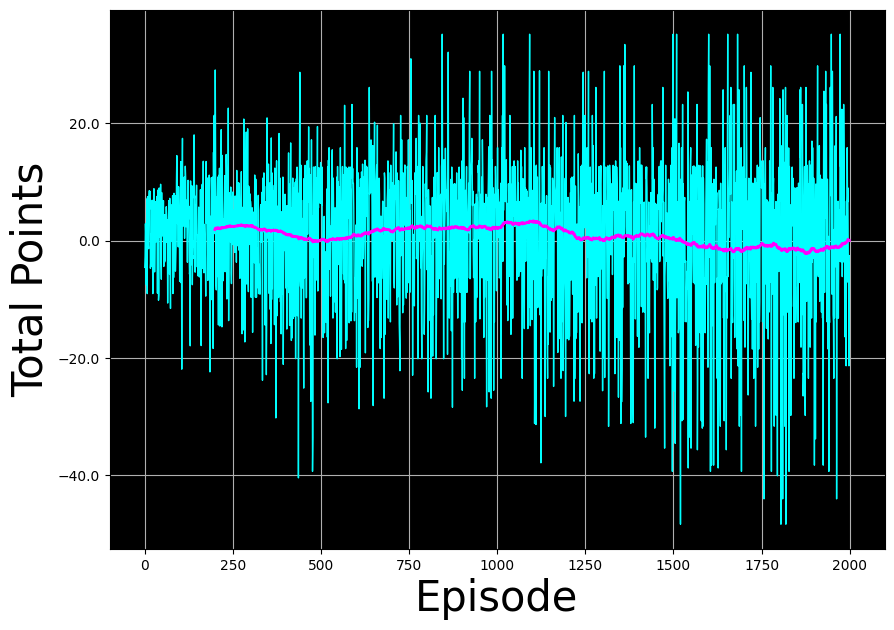

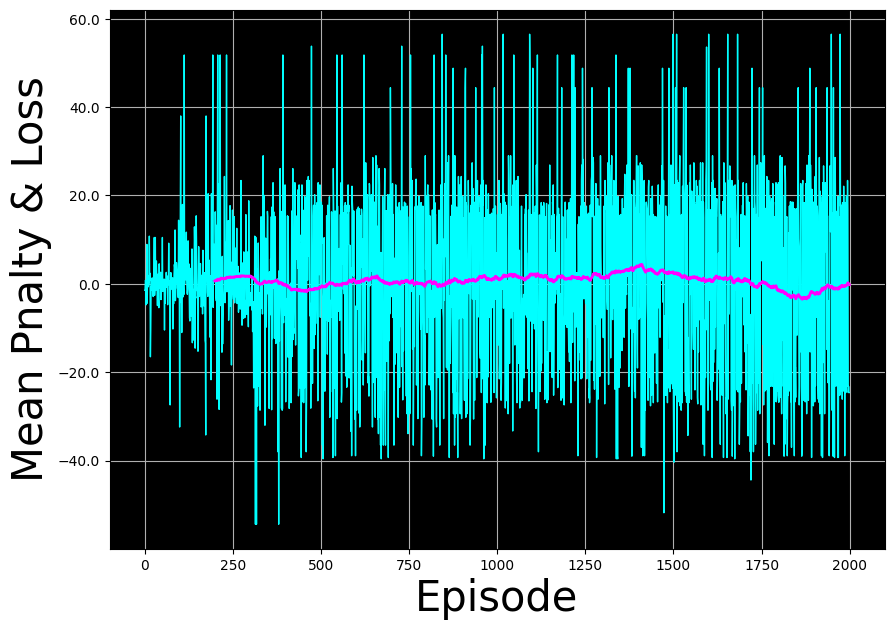

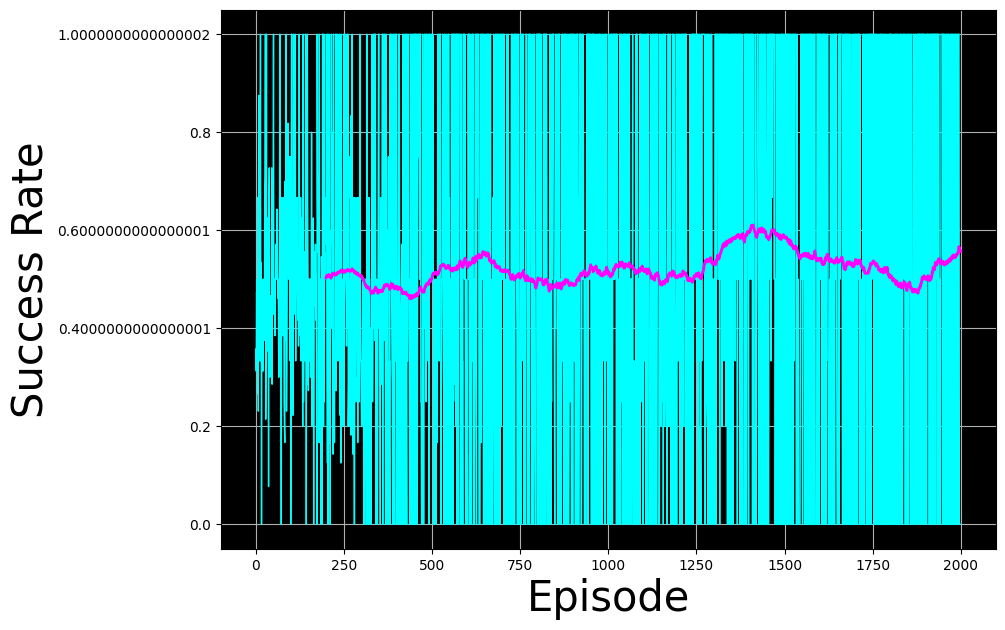

In [1135]:
try:
    plot_history(total_point_history, "Total Points")
    plot_history(pnl_history, "Mean Pnalty & Loss")
    plot_history(success_rate_history, "Success Rate")
except:
    print('No history to plot!')

# Live Testing

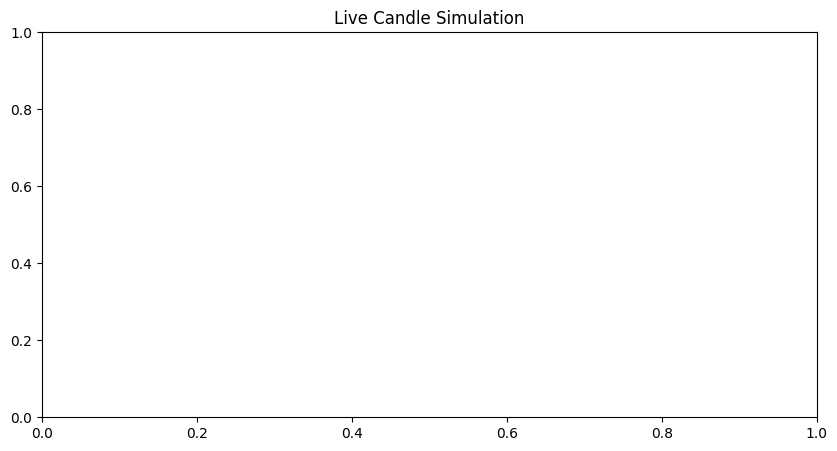

In [1136]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import time

# --- Example candle data (replace this with your real dataframe) ---
data = {
    'Date': pd.date_range("2023-01-01", periods=20, freq="1min"),
    'Open':  [100 + i*0.5 for i in range(20)],
    'High':  [100 + i*0.5 + 0.3 for i in range(20)],
    'Low':   [100 + i*0.5 - 0.2 for i in range(20)],
    'Close': [100 + i*0.5 + (0.1 if i % 2 == 0 else -0.1) for i in range(20)],
    'Volume':[1000 + i*10 for i in range(20)]
}
df = pd.DataFrame(data).set_index("Date")

# --- Parameters ---
update_interval = 1  # seconds per candle

# --- Matplotlib setup ---
fig, ax = plt.subplots(figsize=(10,5))
ax.set_title("Live Candle Simulation")

# keep track of how many candles have been shown
candle_count = [0]  

def update(frame):
    ax.clear()
    ax.set_title("Live Candle Simulation")

    # take first N candles
    n = candle_count[0] + 1
    df_partial = df.iloc[:n]

    # plot them
    mpf.plot(df_partial, type='candle', ax=ax, volume=False, style='charles')

    candle_count[0] = n % len(df)  # loop when reaching end

ani = FuncAnimation(fig, update, interval=update_interval*1000)

plt.show()


## Testing the Model

In [1163]:
lower_tf_data = m5_data_filtered[:12000].copy()
higher_tf_data = m30_data_filtered[:2000].copy()
n_candles_to_test = 200

env = MultiTimeframeForexEnv(
    lower_tf_data=lower_tf_data,
    higher_tf_data=higher_tf_data,
    walk_forward_window=n_candles_to_test,
    lookback_window=LOOKBACK_WINDOW_SIZE,
    # walk_forward_window=100,
    stop_loss_pct=0.0015, #0.0015,
    take_profit_pct=0.0015,
    test=True,
    n_candles_to_test=n_candles_to_test
)




current_state = env.reset()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

x_low, x_high, pos_info = state_to_tensor(current_state, device=device)

q_network = QModel(
    input_dim_low=x_low.shape[2], 
    input_dim_high=x_high.shape[2],
    pos_info_dim=pos_info.shape[1],
    fusion_dim=64
).to(device)

state_dict = torch.load("converged_model.pth", map_location=device)
q_network.load_state_dict(state_dict)

q_network.eval()

QModel(
  (backbone): MultiScaleTransformer(
    (low_encoder): SingleScaleEncoder(
      (input_proj): Linear(in_features=13, out_features=256, bias=True)
      (pos_encoder): PositionalEncoding()
      (encoder_layer): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
      (transformer_encoder): TransformerEncoder(
        (layers): ModuleList(
          (0-4): 5 x TransformerEncoderLayer(
            (self_attn): Multihea

In [1164]:
# current_state['ltf_data']

In [1165]:
action_list = []
current_state = env.reset()
with torch.no_grad():
    for t in tqdm(range(n_candles_to_test-2)):
        # print(current_state['ltf_data'])
        
        # From the current state S choose an action A using an ε-greedy policy
        x_low, x_high, pos_info = state_to_tensor(current_state, device=device)
        q_values = q_network(x_low, x_high, pos_info)
        print('\nq values',q_values[0])
        valid_actions = env._get_valid_actions()
        print('current position',env.current_position)
        print('valid actions', valid_actions)
        
        action = get_action(q_values, valid_actions, epsilon=0)
        print('chosen action', action)
        action_list.append(action)
        # action = np.random.choice(valid_actions)
        
        next_state, _, _, _ = env.step(action)
        current_state = next_state.copy()


  3%|▎         | 5/198 [00:00<00:04, 42.45it/s]


q values tensor([-0.4538,  0.1388,  0.1015,  0.1123], device='cuda:0')
current position 0.0
valid actions [0, 1, 2]
chosen action 1

q values tensor([-0.4780,  0.1121,  0.0842,  0.1229], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5100,  0.1038,  0.0673,  0.1383], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.4173,  0.1423,  0.1245,  0.1768], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5389,  0.1186,  0.1785, -0.0587], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5878,  0.1029,  0.1444, -0.0796], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5621,  0.1078,  0.1812, -0.1129], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5914,  0.0989,  0.1561, -0.1113], device='cuda:0')
current positio

 10%|▉         | 19/198 [00:00<00:02, 60.88it/s]

chosen action 3

q values tensor([-0.5817,  0.0862,  0.0673,  0.0154], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3
	tp meet with 16.300000000000203$ profit

q values tensor([-0.8042,  0.0618,  0.1875, -0.4907], device='cuda:0')
current position 0.0
valid actions [0, 1, 2]
chosen action 2

q values tensor([-0.5339,  0.1395,  0.1108, -0.0078], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.6313,  0.1130,  0.1340, -0.1637], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5509,  0.1426,  0.1140, -0.0165], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.0338,  0.2416, -0.0322,  0.8746], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.0703,  0.2293, -0.0236,  0.7973], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 3
	tp meet with 16.10000000

 23%|██▎       | 46/198 [00:00<00:01, 100.02it/s]


q values tensor([-0.9085,  0.0462,  0.2210, -0.6939], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.9334,  0.0406,  0.2364, -0.7633], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.9663,  0.0391,  0.2590, -0.8291], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 3

q values tensor([-1.0116,  0.0230,  0.2840, -0.9460], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 3

q values tensor([-1.0330,  0.0102,  0.2979, -1.0235], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 3

q values tensor([-1.0475,  0.0038,  0.3096, -1.0751], device='cuda:0')
current position -0.1
valid actions [0, 3]
chosen action 0

q values tensor([-0.8347,  0.0419,  0.1979, -0.5829], device='cuda:0')
current position 0.0
valid actions [0, 1, 2]
chosen action 2

q values tensor([-0.8232,  0.0593,  0.1977, -0.5649], device='cuda:0')
current p

... (8 outputs left out)

 94%|█████████▍| 187/198 [00:01<00:00, 127.84it/s]


q values tensor([-0.5662,  0.0836,  0.1292, -0.1158], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5241,  0.1060,  0.1536, -0.0974], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5440,  0.1006,  0.1678, -0.1500], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5569,  0.0980,  0.1613, -0.1525], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5756,  0.0884,  0.1339, -0.1237], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5568,  0.1017,  0.1556, -0.1378], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5697,  0.0945,  0.2045, -0.2389], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.6299,  0.0858,  0.2215, -0.3344], device='cuda:0')
current position 0

100%|██████████| 198/198 [00:01<00:00, 112.30it/s]


q values tensor([-0.6304,  0.0759,  0.1632, -0.2344], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.6350,  0.0712,  0.1492, -0.2141], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.5866,  0.0943,  0.1786, -0.2120], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.6011,  0.0877,  0.2085, -0.2891], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.6294,  0.0829,  0.2376, -0.3293], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.6771,  0.0741,  0.2502, -0.4109], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3

q values tensor([-0.8170,  0.0570,  0.3016, -0.6253], device='cuda:0')
current position 0.1
valid actions [0, 3]
chosen action 3
	sl meet with -23.299999999999432$ loss

q values tensor([-0.4245,  0.1535,  0.1180,  0.13

In [1147]:
env.current_balance

np.float64(9911.800000000003)

In [1141]:
# len(action_list)
action_list[-10:]

[3, 3, 3, 3, 3, 3, 3, 3, 3, 1]

In [1142]:
q_vals = q_network(x_low, x_high, pos_info)
print('q_vals',q_vals)
mask = torch.full_like(q_values, -1e9)  # very negative
print('mask',mask)
print('valid_actions', valid_actions)

mask[0, valid_actions] = q_values[0, valid_actions]
print('after masking', mask)
act = torch.argmax(mask, dim=1).item()
print(act)

q_vals tensor([[-0.4245,  0.1535,  0.1180,  0.1369]], device='cuda:0',
       grad_fn=<AddmmBackward0>)
mask tensor([[-1.0000e+09, -1.0000e+09, -1.0000e+09, -1.0000e+09]], device='cuda:0')
valid_actions [0, 1, 2]
after masking tensor([[-4.2451e-01,  1.5352e-01,  1.1798e-01, -1.0000e+09]], device='cuda:0')
1


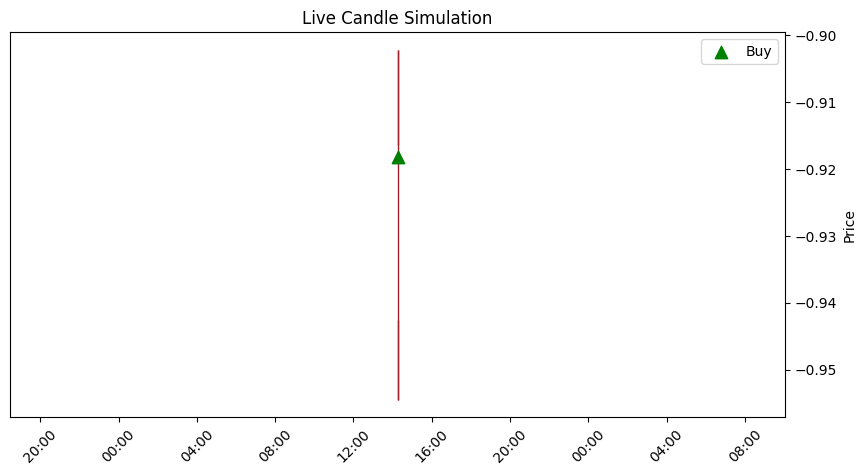

In [1166]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np


data = env.window_generator.get_test_df()
df = pd.DataFrame(data).set_index("time")
df['Open'] = df['mid_o']
df['High'] = df['mid_h']
df['Close'] = df['mid_c']
df['Low'] = df['mid_l']

# --- Example agent actions (0: noop, 1: buy, 2: sell, 3: hold) ---
actions = action_list #np.random.choice([0,1,2,3], size=len(df))

# --- Parameters ---
update_interval = 1  # seconds per candle

# --- Matplotlib setup ---
fig, ax = plt.subplots(figsize=(10,5))
ax.set_title("Live Candle Simulation")

def update(n):
    
    ax.clear()
    ax.set_title("Live Candle Simulation")

    # take first N candles (ensure n>=1)
    start = 0
    if n > 40:
        start = n-40
    df_partial = df.iloc[start:n]
    act_partial = actions[start:n]

    # plot candlesticks
    mpf.plot(df_partial, type='candle', ax=ax, volume=False, style='charles', show_nontrading=True)

    # overlay agent actions on CLOSE price
    for date, close, high, low, act in zip(df_partial.index, 
                                           df_partial['Close'], 
                                           df_partial['High'], 
                                           df_partial['Low'], 
                                           act_partial):
        if act == 1:   # Buy → show above high
            ax.scatter(date, high * 1.002, marker="^", color="green", s=80, label="Buy" if n==1 else "")
        elif act == 2: # Sell → show below low
            ax.scatter(date, low * 0.998, marker="v", color="red", s=80, label="Sell" if n==1 else "")
        elif act == 3: # Hold → show just above close
            ax.scatter(date, close * 1.001, marker="o", color="blue", s=60, label="Hold" if n==1 else "")
        # 0 = noop → nothing

    if n == 1:  # only show legend once
        ax.legend()

ani = FuncAnimation(fig, update,
                    frames=range(1, len(df)+1),  # <-- start from 1
                    interval=update_interval*1000,
                    repeat=True)

HTML(ani.to_jshtml())